## Fractals

Four classic fractals, each a few lines of MATLAB. The first two iterate $z \mapsto z^2 + c$ on a whole grid of complex numbers at once, so there is no loop over pixels: each step updates every point that has not escaped yet.

### The Mandelbrot set

A point $c$ is in the Mandelbrot set when $z_{k+1} = z_k^2 + c$, starting from $z_0 = 0$, stays bounded. Once $|z| > 2$ it escapes for sure, so the picture colors each point by the step at which it escaped.

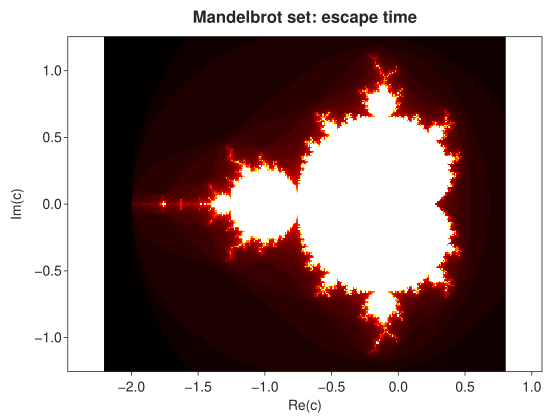

In [ ]:
figure
[re, im] = meshgrid(linspace(-2.2, 0.8, 300), linspace(-1.25, 1.25, 250));
c = re + 1i*im;
z = zeros(size(c));
escape = zeros(size(c));
for k = 1:50
    inside = abs(z) <= 2;
    z(inside) = z(inside).^2 + c(inside);
    escape(inside) = k;
end
imagesc(re(1, :), im(:, 1), escape)
axis xy equal tight
colormap(hot)
title('Mandelbrot set: escape time')
xlabel('Re(c)'), ylabel('Im(c)')

### A Julia set

Fix $c$ and vary the starting point instead: the Julia set of $c$ is the boundary of the starting points that stay bounded. Here $c = -0.8 + 0.156i$.

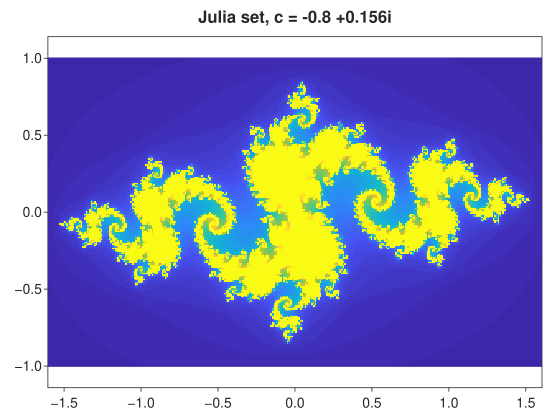

In [ ]:
figure
[jr, ji] = meshgrid(linspace(-1.6, 1.6, 300), linspace(-1, 1, 200));
w = jr + 1i*ji;
cj = -0.8 + 0.156i;
steps = zeros(size(w));
for k = 1:60
    alive = abs(w) <= 2;
    w(alive) = w(alive).^2 + cj;
    steps(alive) = k;
end
imagesc(jr(1, :), ji(:, 1), steps)
axis xy equal tight
colormap(parula)
title(sprintf('Julia set, c = %g %+gi', real(cj), imag(cj)))

### The Barnsley fern

An iterated function system: four affine maps, one picked at random at each step with fixed probabilities. The points the iteration visits draw a fern. Here 600 independent starting points iterate together, a vector at a time, and the picture keeps steps 11 to 20 of each. `rng` fixes the random numbers, so the picture is the same every run.

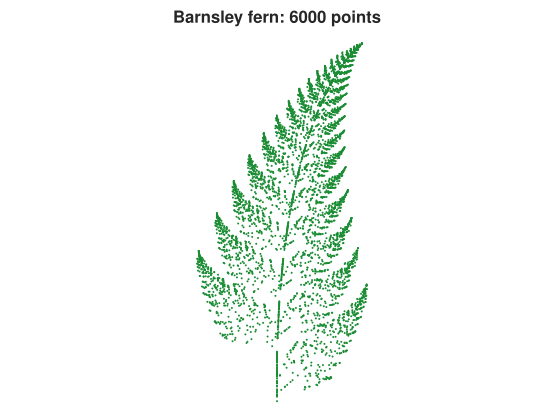

In [ ]:
figure
rng(1);
chains = 600;
fx = zeros(chains, 1); fy = zeros(chains, 1);
P = zeros(0, 2);
for k = 1:20
    r = rand(chains, 1);
    m1 = r < 0.01; m2 = r >= 0.01 & r < 0.86; m3 = r >= 0.86 & r < 0.93; m4 = r >= 0.93;
    gx = zeros(chains, 1); gy = zeros(chains, 1);
    gy(m1) = 0.16*fy(m1);
    gx(m2) = 0.85*fx(m2) + 0.04*fy(m2);  gy(m2) = -0.04*fx(m2) + 0.85*fy(m2) + 1.6;
    gx(m3) = 0.2*fx(m3) - 0.26*fy(m3);   gy(m3) = 0.23*fx(m3) + 0.22*fy(m3) + 1.6;
    gx(m4) = -0.15*fx(m4) + 0.28*fy(m4); gy(m4) = 0.26*fx(m4) + 0.24*fy(m4) + 0.44;
    fx = gx; fy = gy;
    if k > 10
        P = [P; fx, fy];
    end
end
plot(P(:, 1), P(:, 2), '.', 'MarkerSize', 1, 'Color', [0.1 0.55 0.2])
axis equal off
title(sprintf('Barnsley fern: %d points', size(P, 1)))

### The logistic map

$x_{k+1} = r\,x_k(1 - x_k)$ settles to one value for small $r$, then to 2, 4, 8, ... values as $r$ grows, and turns chaotic near $r \approx 3.57$. For each $r$ the diagram plots where the iteration ends up after the transient has died out.

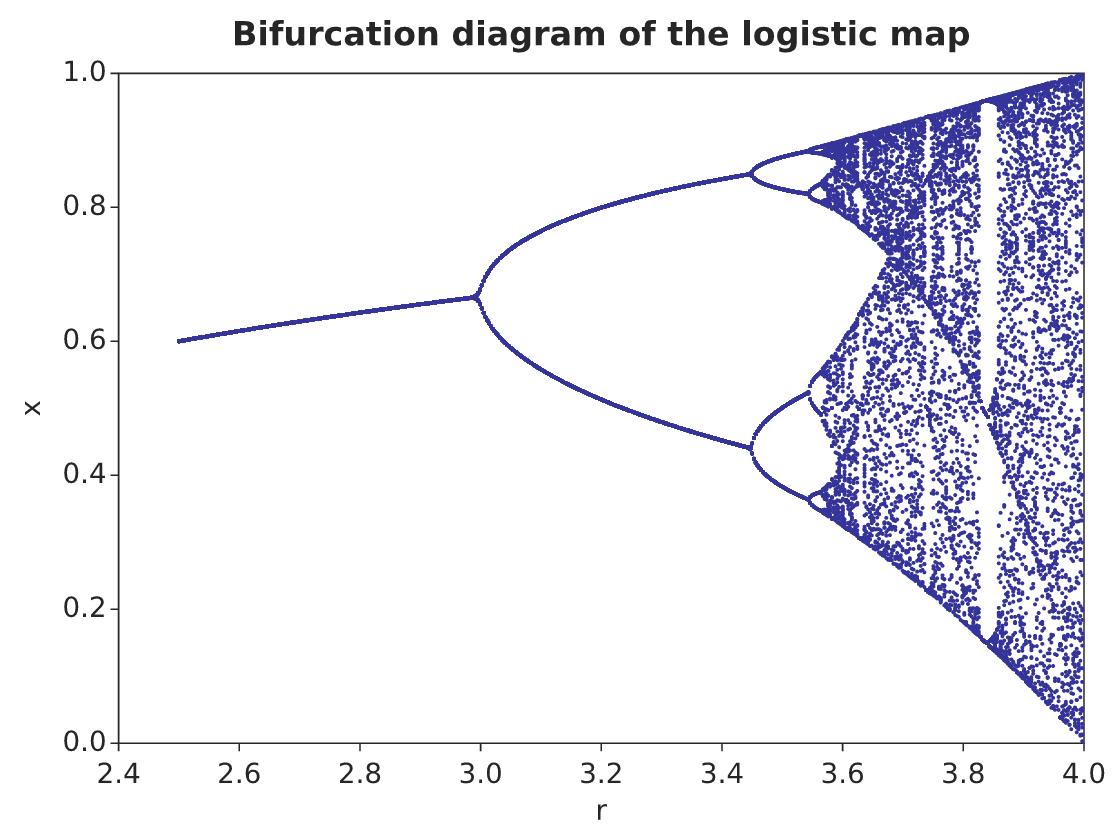

Shown as a PNG: its SVG would be 1.6 MB. For an SVG anyway: sagebrush.figures("svg") (in MATLAB or Magma: sagebrush_figures("svg")).


In [ ]:
figure
rs = linspace(2.5, 4, 500);
xs = 0.5 * ones(size(rs));
for k = 1:300
    xs = rs .* xs .* (1 - xs);
end
R = zeros(60, numel(rs));
X = zeros(60, numel(rs));
for k = 1:60
    xs = rs .* xs .* (1 - xs);
    R(k, :) = rs;
    X(k, :) = xs;
end
plot(R(:), X(:), '.', 'MarkerSize', 1, 'Color', [0.2 0.2 0.6])
xlabel('r'), ylabel('x')
title('Bifurcation diagram of the logistic map')

*Topics after examples in MatRust-Studio (MIT license); the code here is Sagebrush's own.*